# [GSE132208](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE132208)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2020-12-10
> - Modified: 2025-05-11

# 1. Experimental Design

> Epigenetic initiation of the Th17 differentiation programme is promoted by Cxxc finger protein 1.
> - Feng Lin et al. ,Epigenetic initiation of the TH17 differentiation program is promoted by Cxxc finger protein 1.Sci. Adv.5,eaax1608(2019).DOI:10.1126/sciadv.aax1608.
> - Illumina HiSeq X Ten, PE150
> - mm10

| Sample | Cell | Organism | Strain | Tissue | Genotype | Antibody | Replicate |
| - | - | - | - | - | - | - | - |
| WT H3K4me3 | Th17 | Mus musculus | C57BL/6 | naive CD4-derived th17 cells | Wild Type | H3K4me3 | rep1~2 |
| KO H3K4me3 | Th17 | Mus musculus | C57BL/6 | naive CD4-derived th17 cells | Cxxc1 KO | H3K4me3 | rep1~2 |
| WT H3K27me3 | Th17 | Mus musculus | C57BL/6 | naive CD4-derived th17 cells | Wild Type | Cfp1 | rep1~2 |
| KO H3K27me3 | Th17 | Mus musculus | C57BL/6 | naive CD4-derived th17 cells | Cxxc1 KO | Cfp1 | rep1~2 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages({
    library(rtracklayer)
    library(GenomicRanges)
    library(GenomeInfoDb)
    library(EnrichedHeatmap)
    library(RColorBrewer)
    library(viridis)
    library(cowplot)
})

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- path.expand(
    "~/dataset_1/bulk_omics/chipseq_Mm_Th17_Cxxc1_GSE132208/02_output"
)

# 2. Data Import

In [3]:
MARKS <- c("H3K4me3", "Cfp1")

## 1). Reference Resources

In [4]:
suppressPackageStartupMessages({
    library(TxDb.Mmusculus.UCSC.mm10.knownGene)
    library(BSgenome.Mmusculus.UCSC.mm10)
    library(org.Mm.eg.db)
})

# txdb <- TxDb.Mmusculus.UCSC.mm10.knownGene
genome <- BSgenome.Mmusculus.UCSC.mm10

In [5]:
# load reference gene anntotion
gtf_file <- path.expand(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"
)

gtf <- import(gtf_file) |>
    BRGenomics::tidyChromosomes(
        keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, 
    drop.stop.codons = TRUE, 
    taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"),
        value = c("mm10", "vM23"))
)

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


## 2). Blacklist Region

In [6]:
blacklist_file <- path.expand(
    "~/reference/Database/Blacklist/lists/mm10-blacklist.v2.bed"
)

## 3). narrowPeak Import

In [7]:
path.expand(
    "~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_peaks.R"
) |> source()

In [8]:
peaks_files <- file.path(data_dir, "05_peaks") |>
    list.files(pattern = "_peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub("(.*)_peaks\\.narrowPeak", "\\1", basename(.x)))

In [9]:
peaks_list <- lapply(
    peaks_files, load_peaks, dropSex = FALSE, blacklist = blacklist_file, 
    verbose = FALSE)

## 4). bigwig Import

In [10]:
path.expand(
    "~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_bigwig.R"
) |> source()

In [11]:
signals_files <- file.path(data_dir, "07_bigwig") |>
    list.files(pattern = "\\.(bigWig|bw)$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.(bigWig|bw)", "\\1", basename(.x)))

In [12]:
# ~ 2 minutes
signals_list <- lapply(
    signals_files, load_bigwig, dropSex = FALSE, blacklist = blacklist_file, 
    verbose = FALSE)

# 3. Quality Control

## 1). Mapping Statistics

| Sample Name | Raw Reads (M) | Clean Reads (M) | Mapped Reads (M) | Mapping Rate | Duplication Rate | Filter Mapped Reads (M) | Filter Mapping Rate | Fragment Length | Number of Peaks | FRIP |
| - | - | - | - | - | - | - | - | - | - | - |
| - | - | - | - | - | - | - | - | - | - | - |

## 2). Fragment Size Distribution

In [13]:
fragment_size <- file.path(data_dir, "01_stats", "fragment_size.tsv") |>
    read.table(header = TRUE, sep = "\t") |>
    separate(
        Sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    arrange(Genotype, Mark, Replicate) |>
    group_by(Sample) |>
    mutate(Freq = Occurrences / sum(Occurrences)) |>
    ungroup()

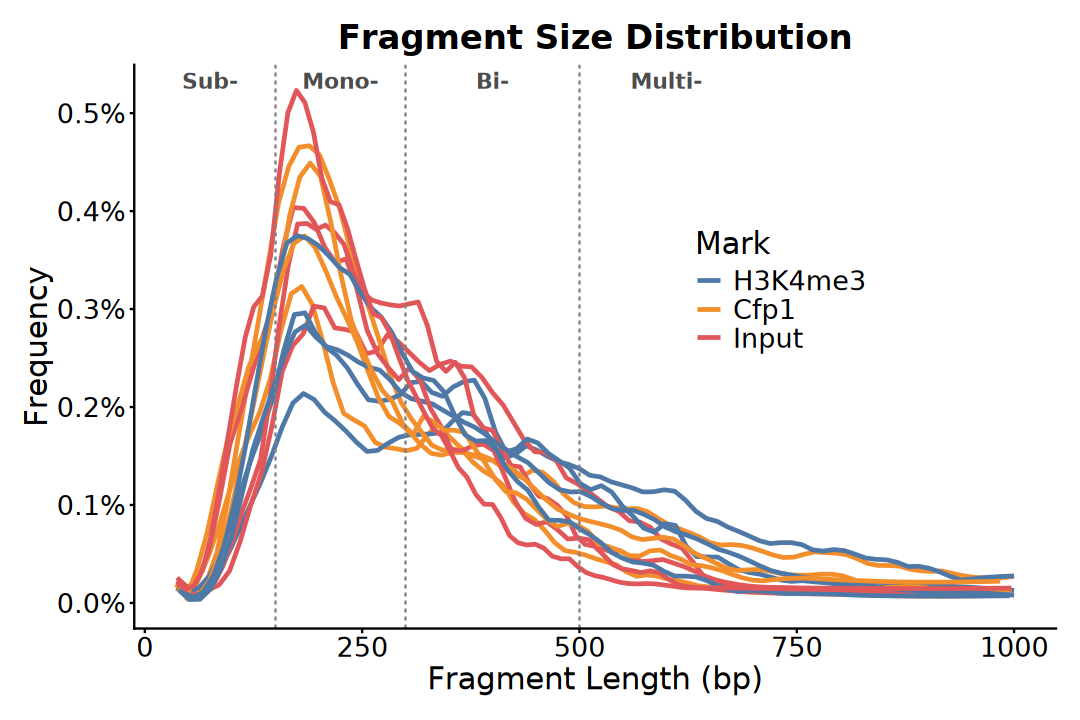

In [14]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(fragment_size, aes(x = Size, y = Freq, group = Sample)) +
    geom_smooth(
        aes(color = Mark), formula = y ~ x, method = "loess", 
        na.rm = TRUE, se = FALSE, span = 0.1, linewidth = 1) +
    geom_vline(
        xintercept = c(150, 300, 500), 
        linetype = "dashed", color = "grey50", linewidth = 0.5) +
    annotate(
        "text", x = c(75, 225, 400, 600), y = Inf,
        label = c("Sub-", "Mono-", "Bi-", "Multi-"),
        vjust = 1.5, size = 4.5, fontface = "bold", color = "grey30") +
    scale_y_continuous(
        limits = c(0, NA), labels = scales::percent_format()) +
    ggthemes::scale_color_tableau(
        palette = "Tableau 10", labels = function(x) gsub("_", " ", x)) +
    labs(
        title = "Fragment Size Distribution", color = "Mark",
        x = "Fragment Length (bp)", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "inside",
        legend.position.inside = c(0.7, 0.6),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 3). Fingerprints

> - Diaz, A., Nellore, A. & Song, J.S. CHANCE: comprehensive software for quality control and validation of ChIP-seq data. Genome Biol 13, R98 (2012). https://doi.org/10.1186/gb-2012-13-10-r98

In [15]:
# Cumulative Distribution Function
plot_df <- file.path(data_dir, "01_stats", "fingerprint.tsv") |>
    read.table(
        header = TRUE, sep = "\t", check.names = FALSE, comment.char = "#") |>
    pivot_longer(
        cols = everything(), names_to = "Sample", values_to = "Counts") |>
    separate(
        Sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    arrange(Sample, Counts) |>
    group_by(Sample) |>
    mutate(
        cum_reads = cumsum(Counts),
        fraction_reads = cum_reads / last(cum_reads),
        fraction_bins = row_number() / n()) |>
    ungroup()

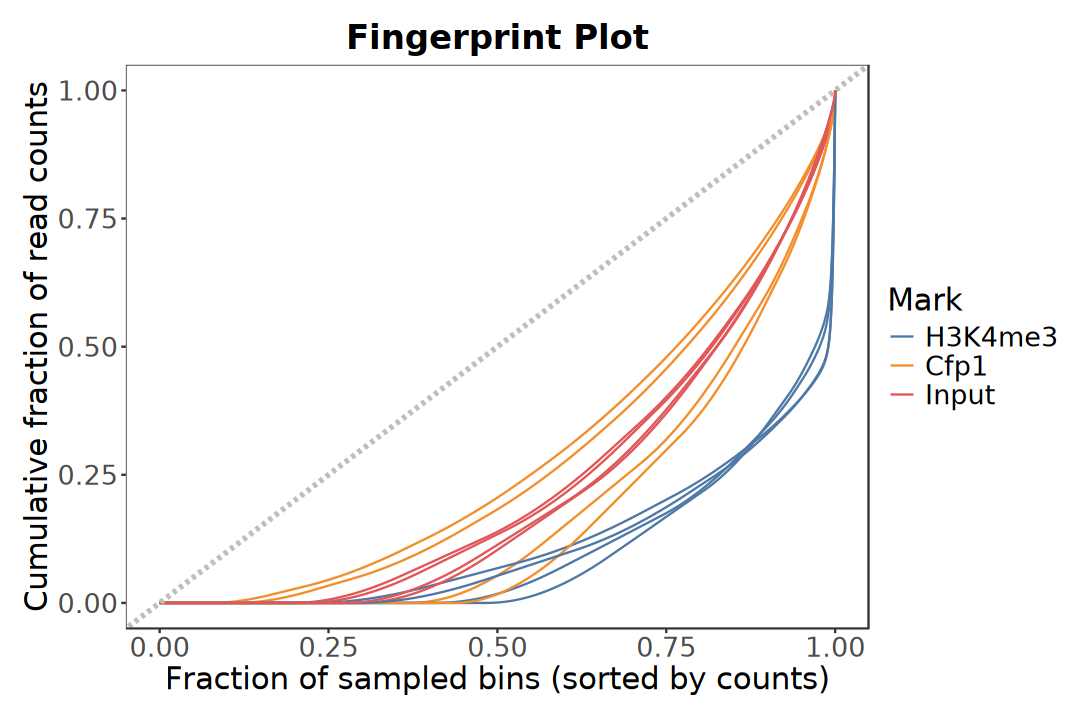

In [16]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = fraction_bins, y = fraction_reads, group = Sample)) +
    geom_line(aes(color = Mark)) +
    geom_abline(
        slope = 1, intercept = 0, color = "gray", 
        linetype = "dashed", linewidth = 1.2) +
    ggthemes::scale_color_tableau(palette = "Tableau 10") +
    labs(
        title = "Fingerprint Plot",
        x = "Fraction of sampled bins (sorted by counts)", 
        y = "Cumulative fraction of read counts") +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing.x = unit(0, "lines"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). TSS Enrichment Score

In [17]:
compute_tss_score <- function(
    matrix_file, sample, bs = 10, flank = 2000, verbose = TRUE) {

    mat <- matrix_file |> 
        read.table(header = FALSE, sep = "\t", skip = 3) |>
        as.matrix()

    profile <- colMeans(mat, na.rm = TRUE)
    flank_bins <- as.integer(100 / bs)

    background <- mean(c(head(profile, flank_bins), tail(profile, flank_bins)))

    norm_profile <- profile / background

    center_bin <- as.integer(flank / bs)
    tss_score <- mean(norm_profile[center_bin:(center_bin + 1)])
    if (verbose) {
        message(sample, " TSS Enrichment Score: ", round(tss_score, 2))
    }

    data.frame(
        Position = -flank + (seq_along(profile) - 0.5) * bs, 
        Signal = profile, 
        Sample = sample, 
        TSS_Score = tss_score, 
        Label = paste0(sample, " (Score: ", round(tss_score, 2), ")")
    )
}

In [18]:
matrix_files <- file.path(data_dir, "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

In [19]:
profiles_list <- purrr::imap(matrix_files, compute_tss_score)

Th17_Cxxc1_KO_rep1_Cfp1 TSS Enrichment Score: 2.97

Th17_Cxxc1_KO_rep1_H3K4me3 TSS Enrichment Score: 10.82

Th17_Cxxc1_KO_rep1_Input TSS Enrichment Score: 1.69

Th17_Cxxc1_KO_rep2_Cfp1 TSS Enrichment Score: 3.35

Th17_Cxxc1_KO_rep2_H3K4me3 TSS Enrichment Score: 11.46

Th17_Cxxc1_KO_rep2_Input TSS Enrichment Score: 1.69

Th17_Cxxc1_WT_rep1_Cfp1 TSS Enrichment Score: 3.02

Th17_Cxxc1_WT_rep1_H3K4me3 TSS Enrichment Score: 6.19

Th17_Cxxc1_WT_rep1_Input TSS Enrichment Score: 1.4

Th17_Cxxc1_WT_rep2_Cfp1 TSS Enrichment Score: 3.24

Th17_Cxxc1_WT_rep2_H3K4me3 TSS Enrichment Score: 6.79

Th17_Cxxc1_WT_rep2_Input TSS Enrichment Score: 1.35



In [20]:
profile_df <- do.call(rbind, profiles_list) |>
    separate(
        Sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    arrange(Genotype, Mark, Replicate) |>
    mutate(
        Sample = forcats::fct_inorder(as.character(Sample)), 
        Label = sub("BMC_Ints11_(.*)", "\\1", Label), 
        Label = forcats::fct_inorder(as.character(Label)))

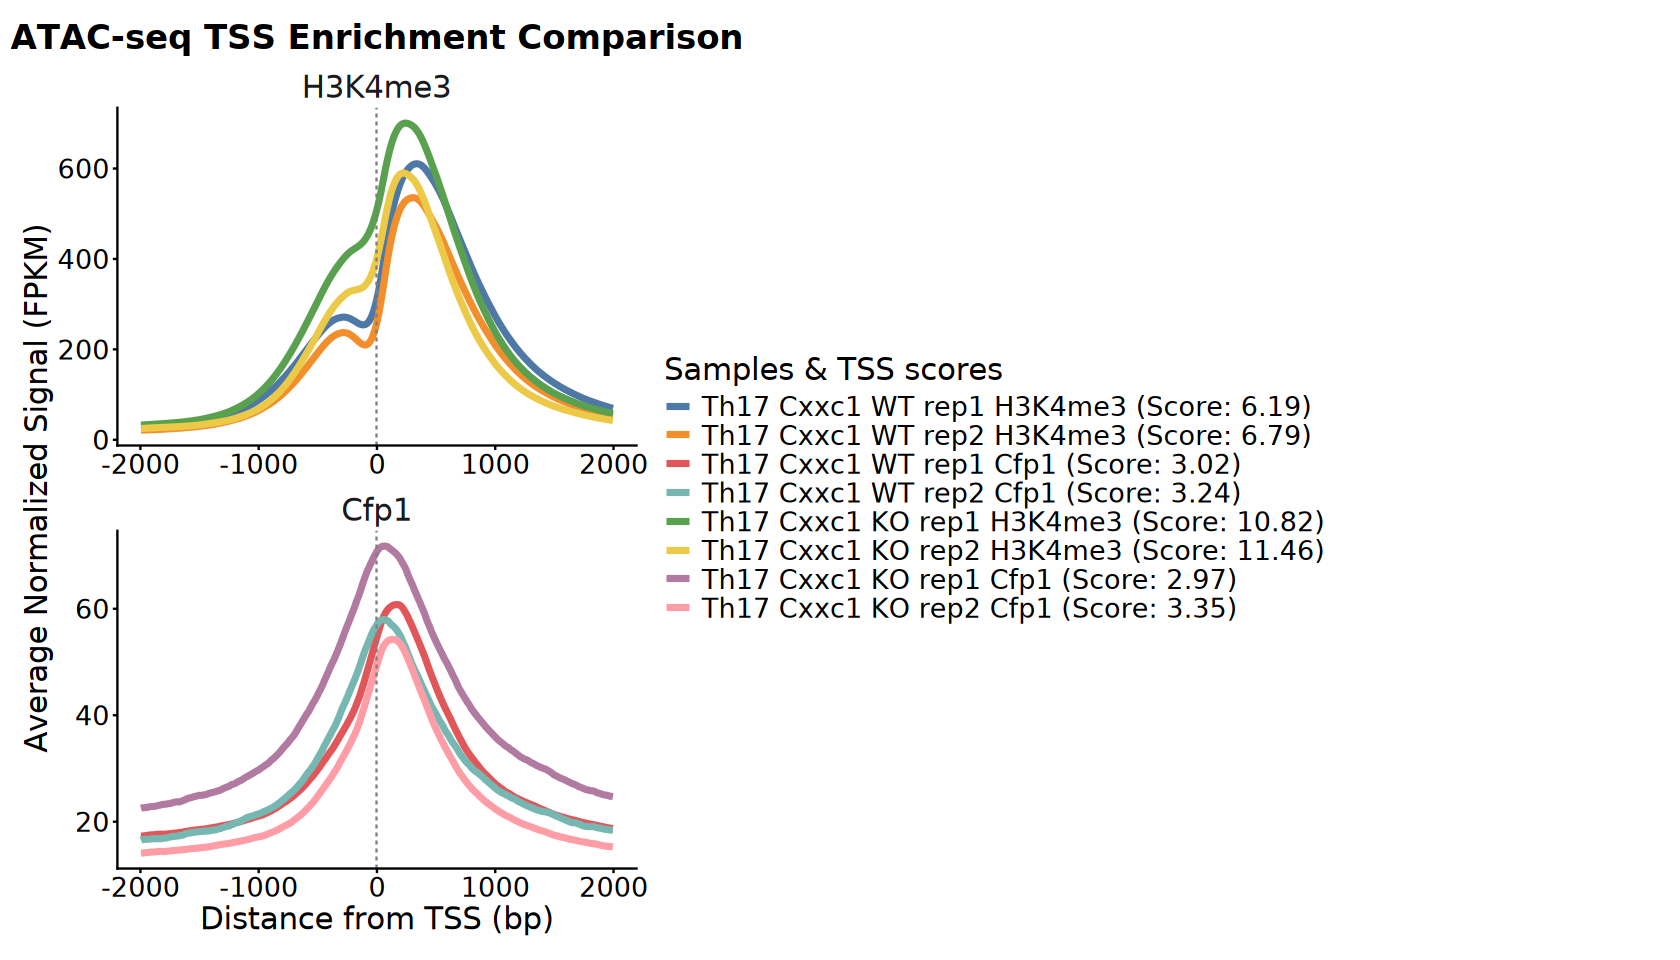

In [21]:
options(repr.plot.width = 14, repr.plot.height = 8)

profile_df |>
    filter(Mark != "Input") |>
ggplot(aes(x = Position, y = Signal)) +
    geom_line(aes(color = Label), linewidth = 1.5) +
    geom_vline(xintercept = 0, linetype = "dashed", color = "gray50") +
    facet_wrap(~ Mark, scales = "free", ncol = 1) +
    ggthemes::scale_color_tableau(
        palette = "Tableau 10", labels = function(x) gsub("_", " ", x)) +
    guides(color = guide_legend(ncol = 1)) +
    labs(
        title = "ATAC-seq TSS Enrichment Comparison",
        color = "Samples & TSS scores",
        x = "Distance from TSS (bp)",
        y = "Average Normalized Signal (FPKM)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 15, 1, 1), "line"),
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 5). Peak Width

In [22]:
EFFECTIVE_GENOME_SIZE <- seqinfo(genome) |>
    keepStandardChromosomes() |>
    dropSeqlevels(c("chrM")) |>
    seqlengths() |>
    sum()

In [23]:
peaks_stats <- map_dfr(names(peaks_list), function(idx) {
    peaks <- peaks_list[[idx]]
    data.frame(
        sample = idx, 
        number_peak = length(peaks),
        min_width = min(width(peaks)),
        max_width = max(width(peaks)),
        mean_width = mean(width(peaks)),
        median_width = median(width(peaks)),
        genome_coverage = sum(width(peaks))
    )
}) |> 
    mutate(
        genome_coverage = round(
            genome_coverage / EFFECTIVE_GENOME_SIZE * 100, 2))

peaks_stats

sample,number_peak,min_width,max_width,mean_width,median_width,genome_coverage
<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>
Th17_Cxxc1_KO_rep1_Cfp1,2743,367,2346,645.6318,582.0,0.06
Th17_Cxxc1_KO_rep1_H3K4me3,13993,421,11838,1741.2665,1630.0,0.89
Th17_Cxxc1_KO_rep2_Cfp1,3526,262,1687,443.4538,397.0,0.06
Th17_Cxxc1_KO_rep2_H3K4me3,13545,334,8579,1472.7093,1373.0,0.73
Th17_Cxxc1_WT_rep1_Cfp1,4664,329,2593,601.6651,525.5,0.10
Th17_Cxxc1_WT_rep1_H3K4me3,14187,351,63097,1932.0715,1724.0,1.01
Th17_Cxxc1_WT_rep2_Cfp1,4439,275,2111,499.9538,441.0,0.08
Th17_Cxxc1_WT_rep2_H3K4me3,15060,282,55281,1710.9122,1514.5,0.95


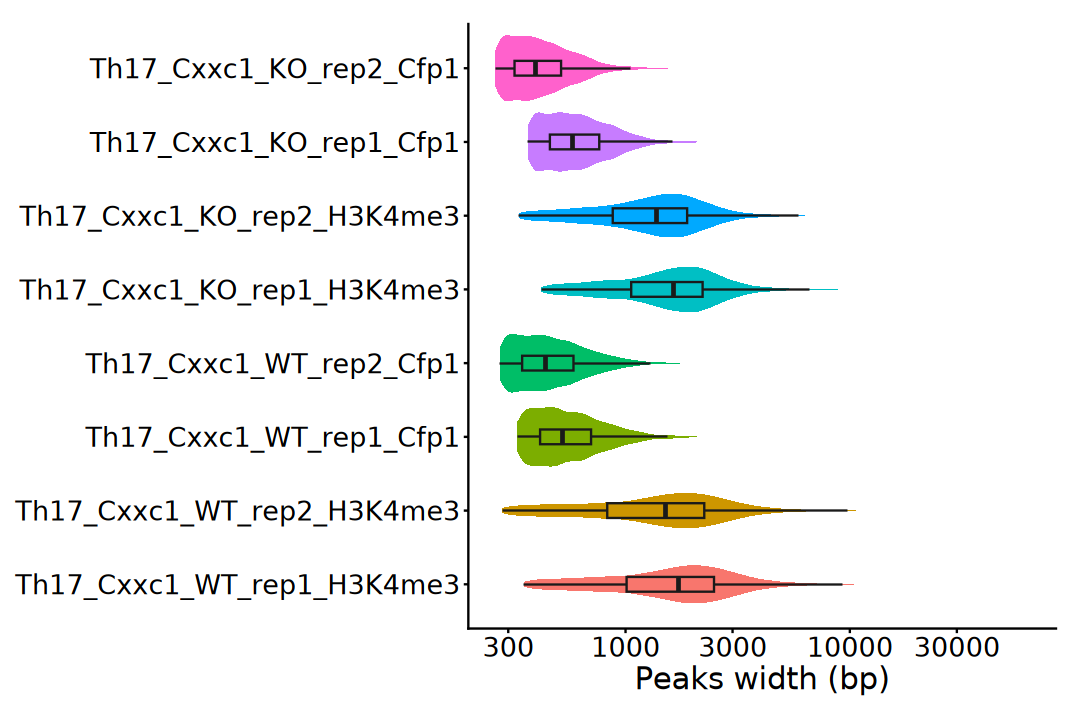

In [24]:
options(repr.plot.width = 9, repr.plot.height = 6)

map_dfr(names(peaks_list), function(idx) {
    tibble(sample = idx, width = width(peaks_list[[idx]]))
}) |> 
    mutate(sample = factor(sample, levels = levels(profile_df$Sample))) |>
ggplot(aes(x = sample, y = width, fill = sample)) +
    geom_violin(trim = TRUE, color = NA) +
    geom_boxplot(width = 0.2, color = "grey10", outliers = FALSE) +
    scale_y_log10() +
    coord_flip() +
    ggthemes::scale_color_tableau(palette = "Tableau 10") +
    labs(x = NULL, y = "Peaks width (bp)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "none", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 6). Replicate Consistency

In [25]:
# ------------------------------------------------------------------------------
# Function: summarize_peak_overlaps
#
# Description:
# Summarize the overlap composition of peak sets across replicates.
#
# Arguments:
#   peaks_list : named list of GRanges.
#   peaks      : short names used for display and ordering.
#                Default: rep1, rep2, ..., repN.
# ------------------------------------------------------------------------------
summarize_peak_overlaps <- function(
    peaks_list, peaks = paste0("rep", seq_along(peaks_list)), 
    ignore.strand = TRUE) {

    names(peaks_list) <- peaks

    comb_levels <- unlist(
        lapply(seq_along(peaks), function(i) {
            combn(peaks, i, FUN = paste, collapse = "&")
        }), use.names = FALSE)

    ol <- lapply(peaks_list, function(gr) {
            names(gr) <- gr$name
            return(gr)
        }) |>
            ChIPpeakAnno::findOverlapsOfPeaks(ignore.strand = ignore.strand)

    ol$venn_cnt[, c(names(peaks_list), "Counts"), drop = FALSE] |>
        as.data.frame(stringsAsFactors = FALSE) |>
        dplyr::rename_with(~ peaks, .cols = names(peaks_list)) |>
        dplyr::rowwise() |>
        dplyr::mutate(
            Combination = {
                present <- peaks[c_across(dplyr::all_of(peaks)) == 1]
                if (length(present) == 0) {
                    NA_character_
                } else {
                    paste(present, collapse = "&")
                }
            }
        ) |>
        dplyr::ungroup() |>
        dplyr::mutate(
            Combination = factor(Combination, levels = comb_levels)) |>
        dplyr::filter(!is.na(Combination)) |>
        dplyr::select(Combination, Counts) |>
        as.data.frame()
}

In [26]:
overlap_summary <- names(peaks_list) |>
    data.frame(sample = _) |>
    separate(
        sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    column_to_rownames("sample") |>
    split(~ Genotype + Mark, drop = TRUE) |>
    purrr::imap_dfr(function(df, group_name) {
        group <- unique(df$Genotype)
        mark  <- unique(df$Mark)
        summarize_peak_overlaps(
            peaks_list[rownames(df)]) |>
            mutate(Mark = mark, Genotype = group, .before = 1)
    })

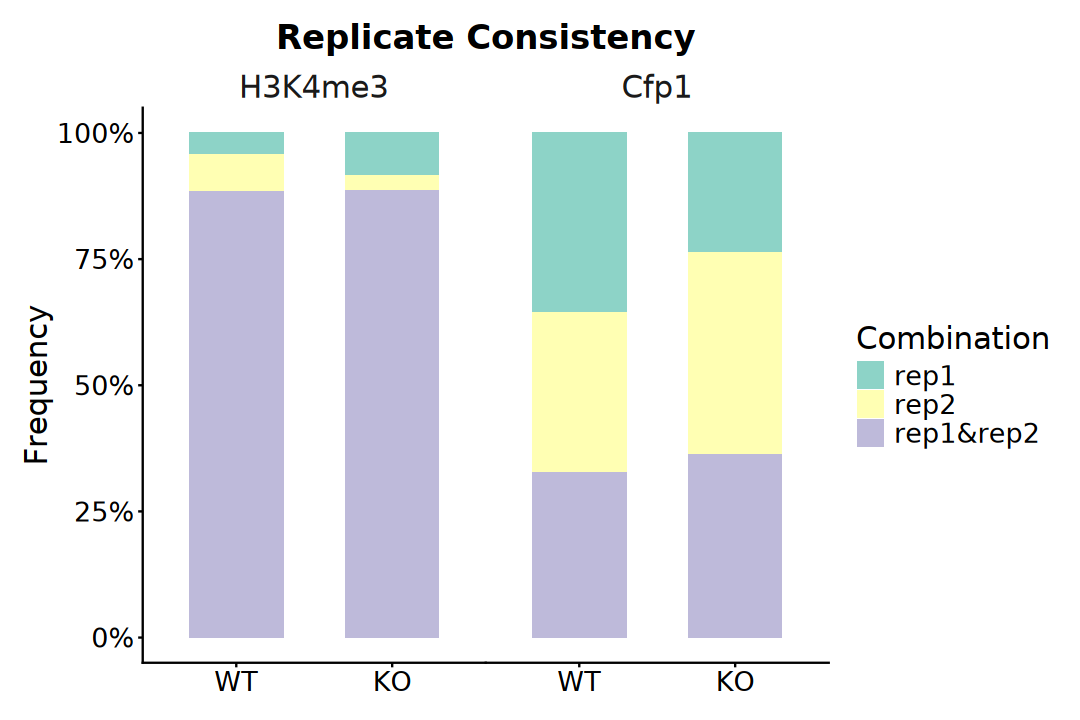

In [27]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(overlap_summary, aes(x = Genotype, y = Counts, fill = Combination)) +
    geom_bar(stat = "identity", position = "fill", width = 0.6) +
    facet_wrap(~ Mark, nrow = 1, strip.position = "top") +
    scale_y_continuous(labels = scales::percent_format()) +
    scale_fill_brewer(palette = "Set3") +
    labs(title = "Replicate Consistency", x = NULL, y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing.x = unit(0, "lines"),
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 4. Genome-wide Landscape

## 1). Global Signal

In [28]:
signal_mat <- file.path(
    data_dir, "09_count", "bins_10kb.counts.tsv") |>
    read_tsv(comment = "", show_col_types = FALSE) |>
    rename_with(~ stringr::str_remove_all(.x, "^#|'")) |>
    unite("pos", chr, start, end, sep = "_") |>
    column_to_rownames("pos") |>
    as.matrix()

In [29]:
dim(signal_mat)

keep <- rowSums(!is.finite(signal_mat)) == 0L & rowSums(signal_mat != 0) > 0L

signal_mat <- signal_mat[keep, , drop = FALSE]

dim(signal_mat)

[1] 273122     12

[1] 259438     12

In [30]:
coldata <- data.frame(sample = colnames(signal_mat)) |>
    separate(
        sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    column_to_rownames("sample")

In [31]:
pca <- signal_mat |> log1p() |> scale() |> t() |>
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(pca$sdev^2 / sum(pca$sdev^2) * 100, 2)

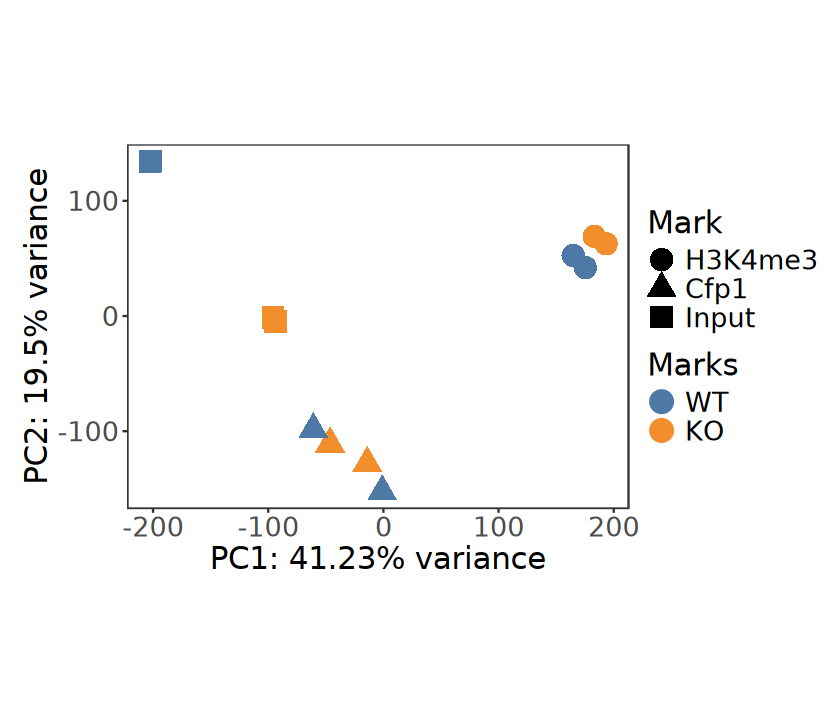

In [32]:
options(repr.plot.width = 7, repr.plot.height = 6)

pca$x |>
    as.data.frame() |>
    rownames_to_column(var = "sample") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
ggplot(aes(PC1, PC2, color = Genotype, shape = Mark)) +
    geom_point(size = 6) +
    coord_fixed() +
    ggthemes::scale_color_tableau("Tableau 10") +
    xlab(paste0("PC1: ", per_var[1], "% variance")) +
    ylab(paste0("PC2: ", per_var[2], "% variance")) +
    labs(color = "Marks") +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [33]:
ac <- dplyr::select(coldata, Mark, Replicate, Genotype)

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(coldata$Genotype)),
    levels(coldata$Genotype))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(coldata$Replicate)),
    levels(coldata$Replicate))
mark_colors <- setNames(
    scales::brewer_pal(palette = "Set3")(nlevels(coldata$Mark)),
    levels(coldata$Mark))

anno_colors <- list(
    Genotype = group_colors,
    Replicate = replicate_colors, 
    Mark = mark_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [34]:
cor_mat <- cor(signal_mat, method = "spearman")

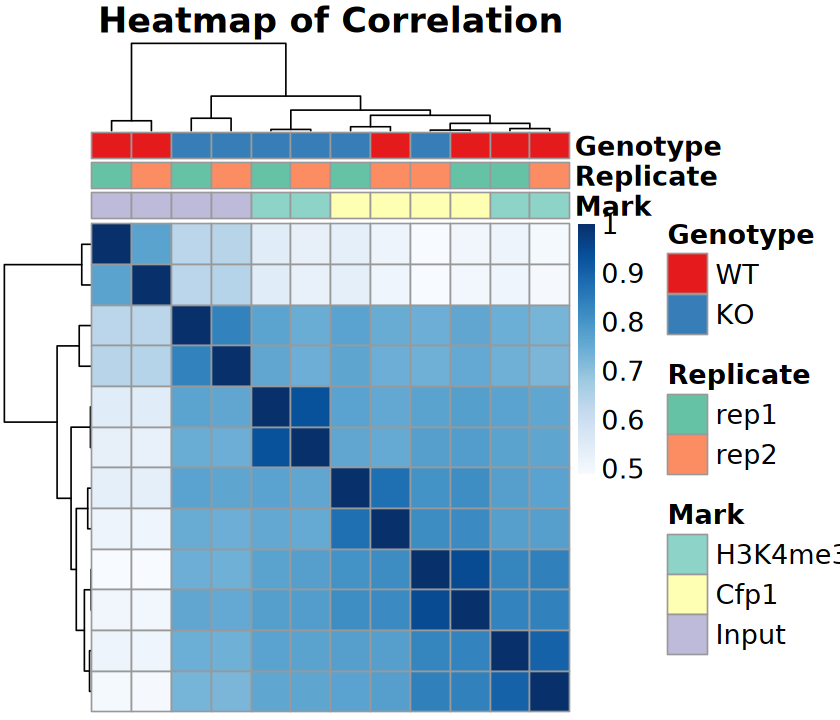

In [35]:
options(repr.plot.width = 7, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [36]:
signal_norm <- signal_mat |> log1p() |> scale()

bin_var <- matrixStats::rowVars(signal_norm)

top_idx <- kit::topn(bin_var, n = 2000L, decreasing = TRUE)

selected <- top_idx[bin_var[top_idx] > 0]

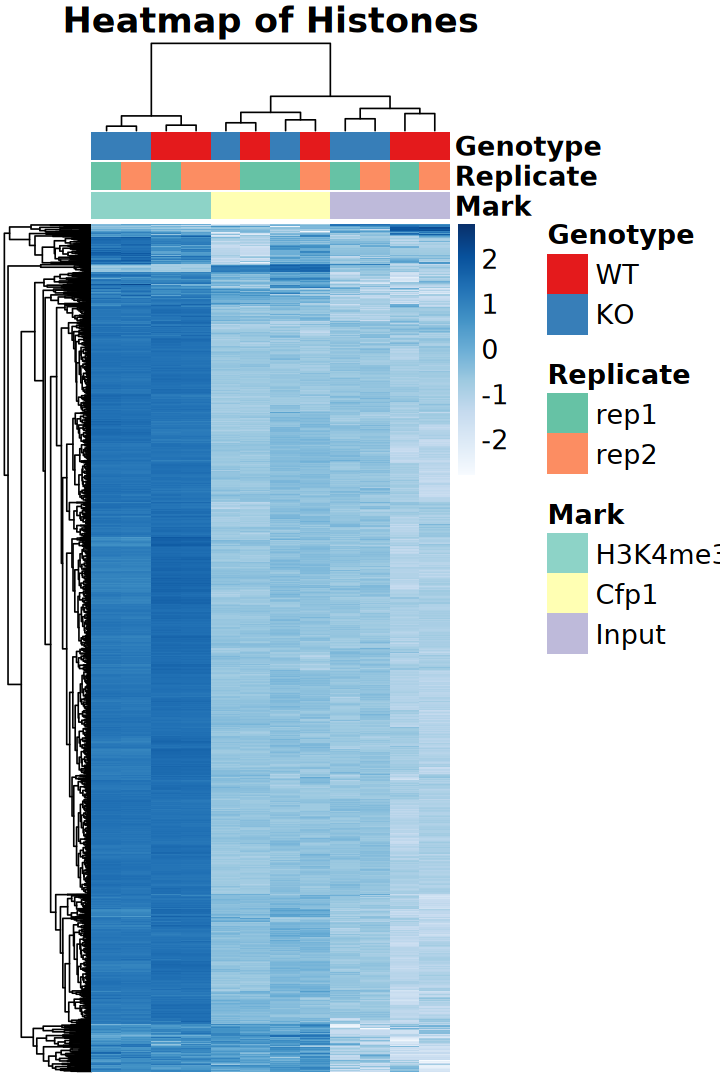

In [37]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    signal_norm[selected, ], 
    scale = "row", 
    col = colors, 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    show_colnames = FALSE, 
    show_rownames = FALSE, 
    fontsize = 16, 
    main = "Heatmap of Histones"
)

# 5. Peak Annotation

### ChIPseeker

In [38]:
suppressPackageStartupMessages(library(ChIPseeker))

In [39]:
# Downstream within 3kb
feature_order <- c(
    "Promoter", "5UTR", "3UTR", "Exon", "Intron", 
    "Downstream", "Intergenic"
)

peaks_annotated_list <- lapply(
    peaks_list, 
    annotatePeak, 
    TxDb = txdb, 
    level = "transcript", 
    tssRegion = c(-2000, 500), 
    genomicAnnotationPriority = feature_order, 
    verbose = FALSE
)

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>."


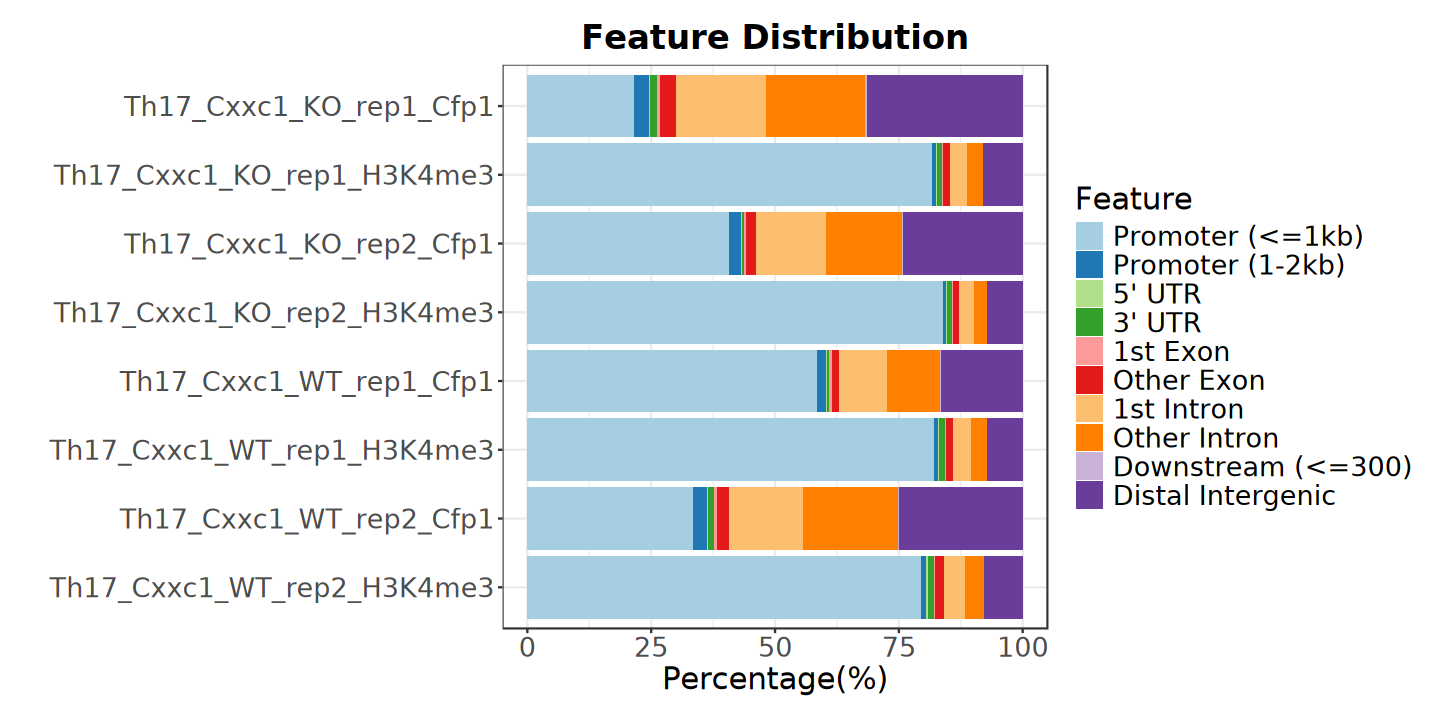

In [40]:
options(repr.plot.width = 12, repr.plot.height = 6)

plotAnnoBar(peaks_annotated_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

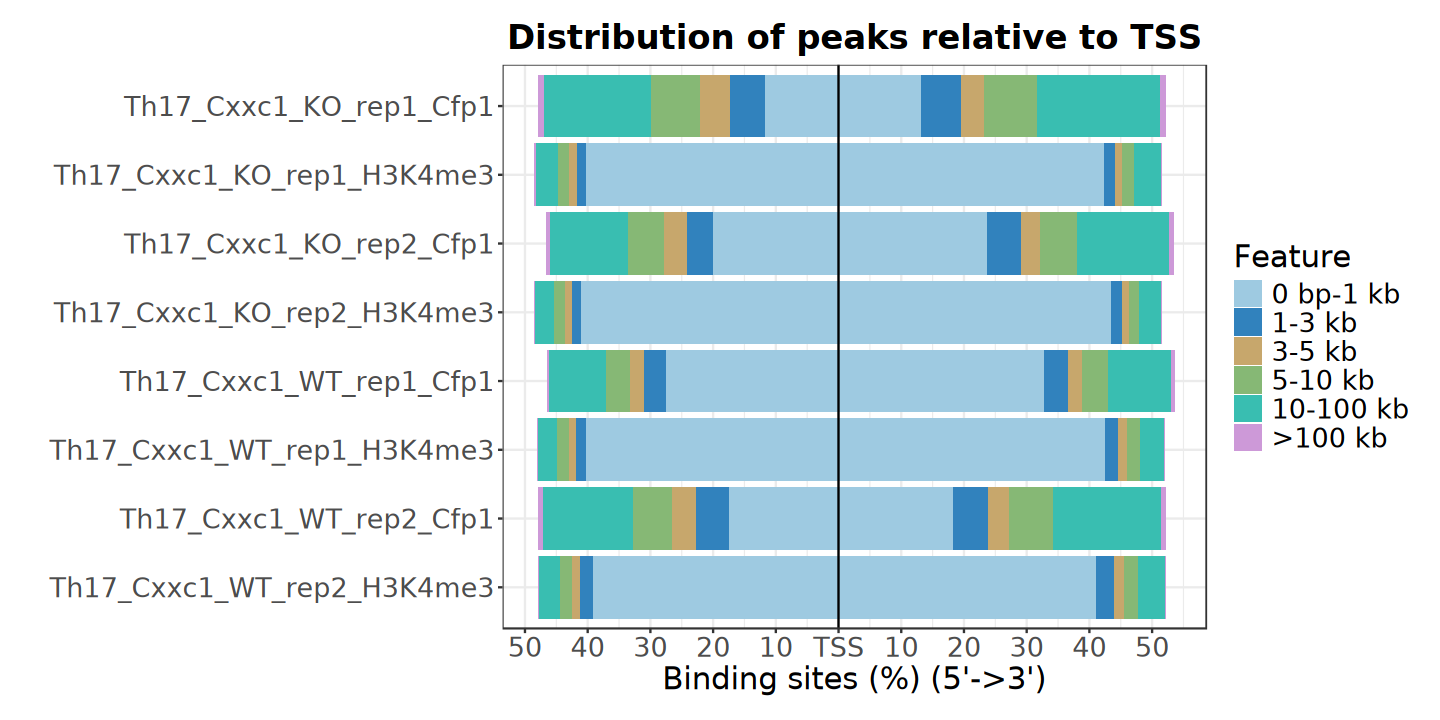

In [41]:
options(repr.plot.width = 12, repr.plot.height = 6)

plotDistToTSS(
    peaks_annotated_list, title = "Distribution of peaks relative to TSS") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 6. Histone Modification Profiles

## 1). [deepTools](https://github.com/deeptools/deeptools)

## 2). EnrichedHeatmap

In [42]:
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [43]:
GENES <- genes(txdb)

In [44]:
# ~ 40 minutes
gene_mat_list <- lapply(
    signals_list, 
    normalizeToMatrix, 
    GENES, 
    value_column = "score", 
    mean_mode = "w0", 
    extend = 2000, 
    w = 50, 
    target_ratio = 0.4, 
    background = 0, 
    smooth = FALSE
)

In [45]:
sample_order <- levels(profile_df$Sample)

In [46]:
gene_mat_list <- gene_mat_list[sample_order]

In [47]:
gene_order <- order(
    enriched_score(gene_mat_list[["Th17_Cxxc1_WT_rep1_H3K4me3"]]),
    decreasing = TRUE
)

In [48]:
mark_colors <- ggthemes::tableau_color_pal("Tableau 20")(
    length(gene_mat_list)) |> 
    setNames(names(gene_mat_list)
)

color_fun <- lapply(names(gene_mat_list), function(mark) {
    limit <- gene_mat_list[[mark]] |>
        quantile(0.99, na.rm = TRUE)
    circlize::colorRamp2(
        c(0, limit), c("#FFFFFF", mark_colors[[mark]]))
})

names(color_fun) <- names(gene_mat_list)

In [49]:
ht_list <- lapply(names(gene_mat_list), function(mark) {
    EnrichedHeatmap(
        gene_mat_list[[mark]], 
        name = mark, 
        column_title = mark, 
        col = color_fun[[mark]], 
        cluster_rows = FALSE, 
        row_order = gene_order, 
        show_row_names = FALSE, 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"), 
        width = unit(4, "cm"), 
        top_annotation = HeatmapAnnotation(
            enriched = anno_enriched(
                gp = gpar(lwd = 2, col = mark_colors[mark]), 
                axis_param = list(gp = gpar(fontsize = 10))
            ), 
            height = unit(3, "cm"), 
            show_legend = FALSE
        ), 
        show_heatmap_legend = TRUE, 
        heatmap_legend_param = list(
            title = "FRKM", 
            direction = "horizontal", 
            title_position = "topcenter", 
            legend_width = unit(4, "cm")
        ), 
        use_raster = TRUE)
})

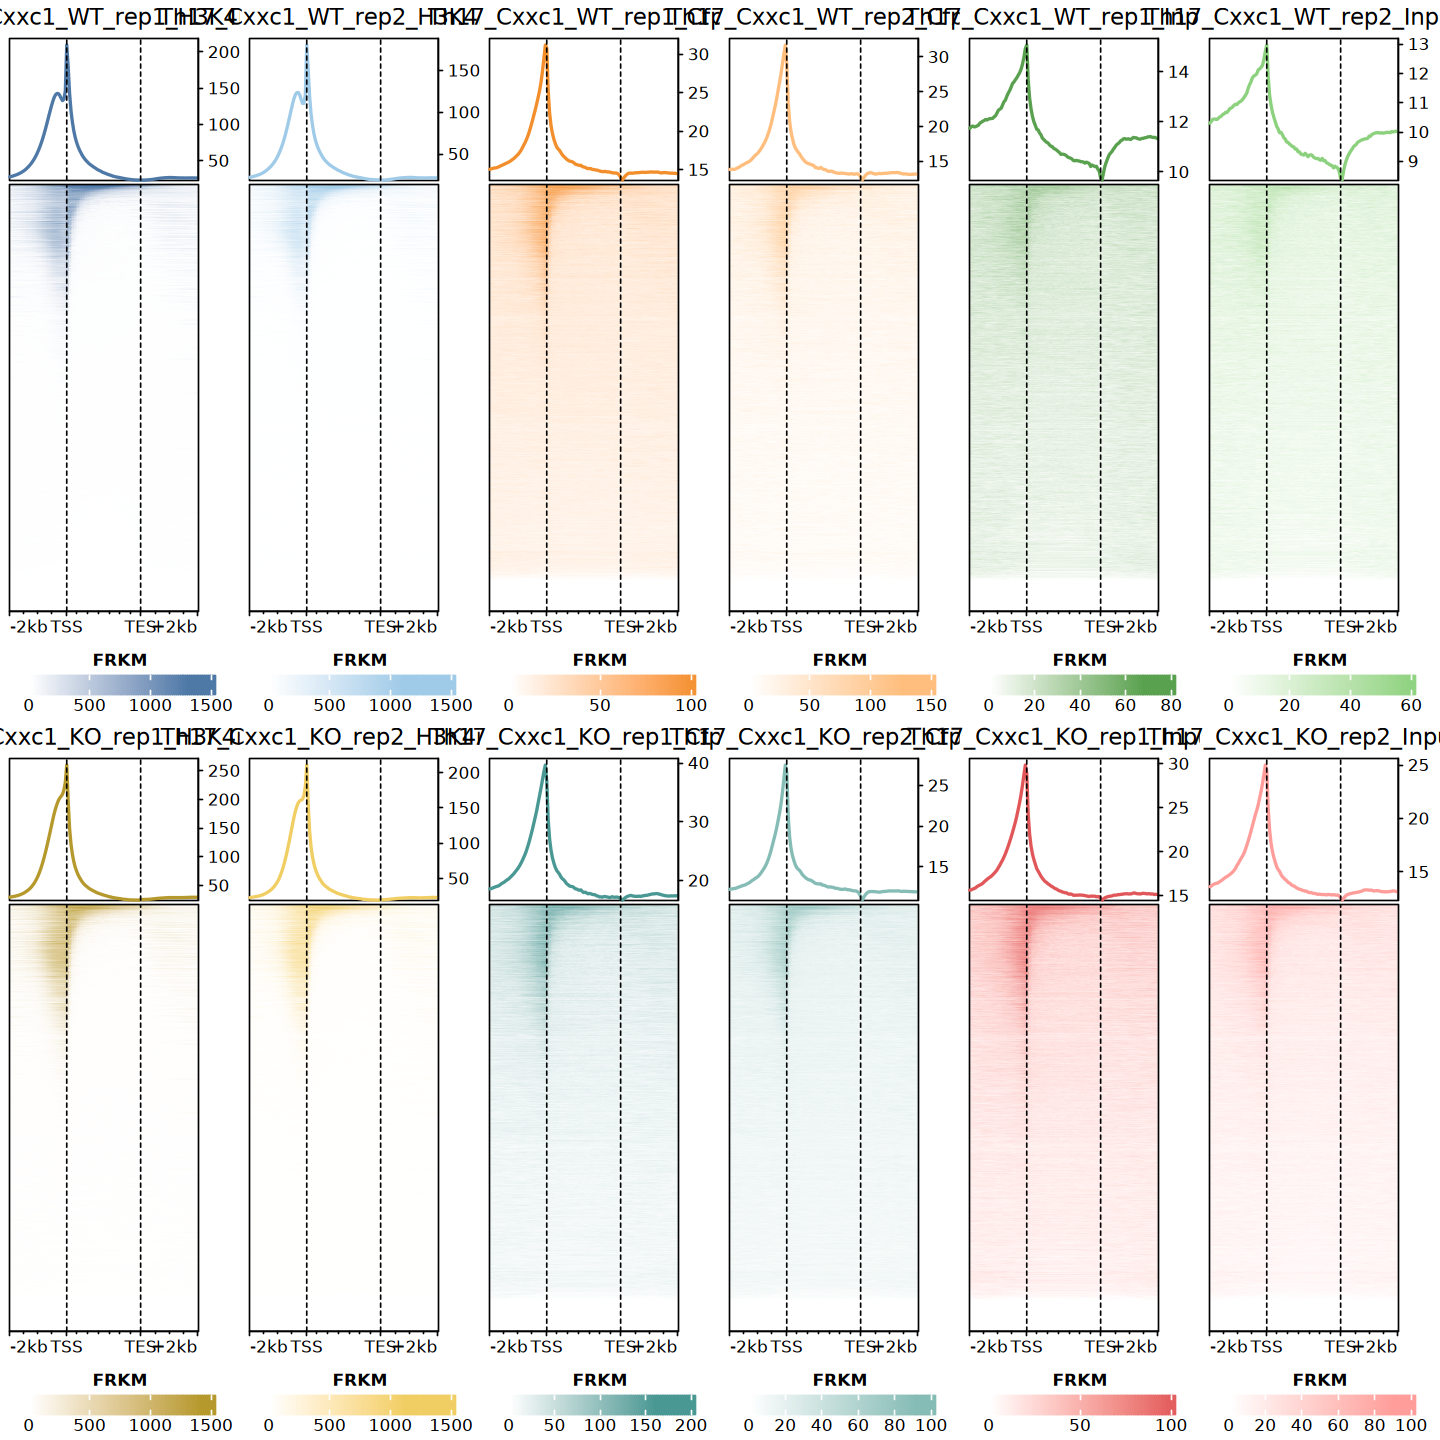

In [50]:
options(repr.plot.width = 12, repr.plot.height = 12)

grid.newpage()

pushViewport(viewport(layout = grid.layout(nrow = 2, ncol = 6)))

for (i in seq_along(ht_list)) {
    pushViewport(viewport(
        layout.pos.row = (i - 1L) %/% 6L + 1L,
        layout.pos.col = (i - 1L) %% 6L + 1L
    ))

    draw(
        ht_list[[i]],
        newpage = FALSE,
        heatmap_legend_side = "bottom"
    )

    popViewport()
}

popViewport()

In [51]:
profiles_df <- purrr::imap_dfr(
    lapply(gene_mat_list, colMeans, na.rm = TRUE),
    function(signal, sample) {
        data.frame(
            Position = seq_along(signal),
            Sample = sample,
            Signal = as.numeric(signal))
}) |>
    separate(
        Sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate))

In [52]:
mat <- gene_mat_list[[1L]]
target_index <- attr(mat, "target_index")

tss_position <- min(target_index) - 0.5
tes_position <- max(target_index) + 0.5

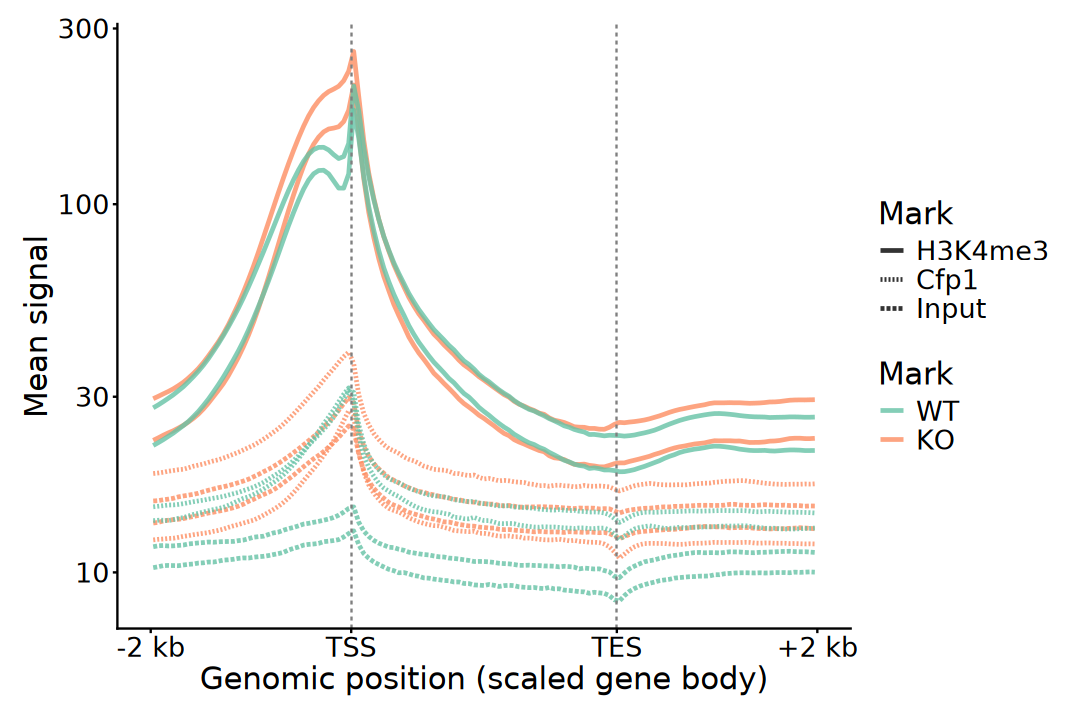

In [53]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_df, aes(Position, Signal, group = Sample)) +
    geom_line(
        aes(color = Genotype, linetype = Mark), 
        linewidth = 1, alpha = 0.8) +
    geom_vline(
        xintercept = c(tss_position, tes_position), 
        linetype = "dashed", color = "gray50") +
    scale_x_continuous(
        limits = c(0.5, ncol(mat) + 0.5),
        breaks = c(0.5, tss_position, tes_position, ncol(mat) + 0.5),
        labels = c("-2 kb", "TSS", "TES", "+2 kb")) +
    scale_y_log10() +
    scale_color_brewer(palette = "Set2") +
    labs(
        x = "Genomic position (scaled gene body)", 
        y = "Mean signal", 
        color = "Mark") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 7. Differential Histone Regions

> Notes:
> 1. Define the Analysis Region
> 2. Obtain the Counts Matrix
> 3. Normalization
> 4. Differential Analysis

In [ ]:
logfc_cutoff <- log2(1.2)
p_cutoff <- 0.05

## a). Manual

> 1. Define the Analysis Region
>     - Peak-based methods
>         - Specific regions of the genome (Promoter, Enhancer, Gene body)
>         - Identify consensus peaks
>     - Window-based approaches
> 2. Obtain the **Raw Counts** Matrix
>     - deeptools, multiBamSummary (PE: fargment, `--samFlagInclude 64`)
>     - bedtools, multicov (?PE: reads)
> 3. Library Size (Normalization)
>     - Total number of mapped reads (default)
>     - Sum of mapped reads in the peaks
> 4. Differential Analysis
>     - DESeq2 (default)
>     - edgeR

In [ ]:
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))

### H3K4me3

In [ ]:
raw_counts <- file.path(
    data_dir, "05_peaks_pooled", 
    "BMC_Ints11_H3K4me3.featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE) |>
    column_to_rownames("Geneid") |>
    dplyr::select(matches("BMC")) |>
    as.matrix()

colnames(raw_counts) <- colnames(raw_counts) |>
    sub("^02_output_chipseq/04_bam/(.*?).bam", "\\1", x = _) |>
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

In [ ]:
coldata <- colnames(raw_counts) |>
    data.frame(sample = _) |>
    separate(
        sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    arrange(Genotype, Mark, Replicate) |>
    column_to_rownames("sample")

coldata$BioID <- interaction(
    coldata$Genotype, coldata$Replicate, sep = "_", drop = TRUE)

coldata$is_chip <- as.integer(coldata$Mark != "Input")
coldata$ko_chip <- as.integer(coldata$Genotype == "KO") * coldata$is_chip

coldata

In [ ]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts[, rownames(coldata), drop = FALSE],
    colData = coldata,
    design = ~ BioID + is_chip + ko_chip
)

In [ ]:
# Library sizes were estimated using the total number of uniquely mapped reads.
library_sizes <- file.path(
    data_dir, "09_count", "library_sizes.tsv") |>
    read.table(header = TRUE, row.names = 1)

library_sizes <- library_sizes[colnames(dds), ]

names(library_sizes) <- colnames(dds)

# Geometric mean
sf <- library_sizes / exp(mean(log(library_sizes)))

paste(names(sf), round(sf, 4), sep = ": ") |> cat(sep = "\n")

In [ ]:
sizeFactors(dds) <- sf

In [ ]:
dds <- DESeq(dds)

In [ ]:
resultsNames(dds)

In [ ]:
res <- results(
    dds, name = "ko_chip", lfcThreshold = logfc_cutoff, alpha = p_cutoff
)

summary(res)

In [ ]:
deseq2_result <- res |> as.data.frame() |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Gain",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Loss",
            TRUE ~ "NS") |> 
            factor(levels = c("Gain", "Loss", "NS"))) |>
    rownames_to_column(var = "peak_id") |>
    separate(
        peak_id, into = c("chr", "start", "end"), 
        sep = ":|-", remove = TRUE) |>
    GRanges()

deseq2_result

In [ ]:
res_tab <- table(deseq2_result$result)

message(
    "Differential histone peaks summary (DEseq2):\n",
    "---------------------------------------------------\n",
    "Gain (higher histone) : ", res_tab["Gain"], "\n",
    "Loss (lower histone)  : ", res_tab["Loss"], "\n",
    "Not significant             : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

### Cfp1

In [ ]:
raw_counts <- file.path(
    data_dir, "05_peaks_pooled", 
    "BMC_Ints11_H3K27me3.featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE) |>
    column_to_rownames("Geneid") |>
    dplyr::select(matches("BMC")) |>
    as.matrix()

colnames(raw_counts) <- colnames(raw_counts) |>
    sub("^02_output_chipseq/04_bam/(.*?).bam", "\\1", x = _) |>
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

In [ ]:
coldata <- colnames(raw_counts) |>
    data.frame(sample = _) |>
    separate(
        sample, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("WT", "KO")), 
        Mark = factor(Mark, levels = c(MARKS, "Input")), 
        Replicate = factor(Replicate)) |>
    arrange(Genotype, Mark, Replicate) |>
    column_to_rownames("sample")

coldata$BioID <- interaction(
    coldata$Genotype, coldata$Replicate, sep = "_", drop = TRUE)

coldata$is_chip <- as.integer(coldata$Mark != "Input")
coldata$ko_chip <- as.integer(coldata$Genotype == "KO") * coldata$is_chip

coldata

In [ ]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts[, rownames(coldata), drop = FALSE],
    colData = coldata,
    design = ~ BioID + is_chip + ko_chip
)

In [ ]:
# Library sizes were estimated using the total number of uniquely mapped reads.
library_sizes <- file.path(
    data_dir, "09_count", "library_sizes.tsv") |>
    read.table(header = TRUE, row.names = 1)

library_sizes <- library_sizes[colnames(dds), ]

names(library_sizes) <- colnames(dds)

# Geometric mean
sf <- library_sizes / exp(mean(log(library_sizes)))

paste(names(sf), round(sf, 4), sep = ": ") |> cat(sep = "\n")

In [ ]:
sizeFactors(dds) <- sf

In [ ]:
dds <- DESeq(dds)

In [ ]:
logfc_cutoff <- log2(1.2)
p_cutoff <- 0.05

In [ ]:
res <- results(
    dds, name = "ko_chip", lfcThreshold = logfc_cutoff, alpha = p_cutoff
)

summary(res)

In [ ]:
deseq2_result <- res |> as.data.frame() |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Gain",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Loss",
            TRUE ~ "NS") |> 
            factor(levels = c("Gain", "Loss", "NS"))) |>
    rownames_to_column(var = "peak_id") |>
    separate(
        peak_id, into = c("chr", "start", "end"), 
        sep = ":|-", remove = TRUE) |>
    GRanges()

deseq2_result

In [ ]:
res_tab <- table(deseq2_result$result)

message(
    "Differential histone peaks summary (DEseq2):\n",
    "---------------------------------------------------\n",
    "Gain (higher histone) : ", res_tab["Gain"], "\n",
    "Loss (lower histone)  : ", res_tab["Loss"], "\n",
    "Not significant             : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

In [ ]:
# dhmp_peaks <- list(
#     Gain = deseq2_result[deseq2_result$result == "Gain", ], 
#     Loss = deseq2_result[deseq2_result$result == "Loss", ])

In [ ]:
# dhmp_peaks <- lapply(
#     dhmp_peaks, annotatePeak, tssRegion = c(-2000, 500), 
#     TxDb = txdb, level = "gene", verbose = FALSE,
#     genomicAnnotationPriority = c(
#         "Promoter", "Exon", "Intron", "Intergenic"))

In [ ]:
# options(repr.plot.width = 9, repr.plot.height = 6)

# plotAnnoBar(dhmp_peaks) +
#     theme_bw() +
#     theme(
#         plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
#         plot.margin = unit(c(1, 1, 1, 1), "line"), 
#         legend.position = "right", 
#         legend.title = element_text(size = 18), 
#         legend.text = element_text(size = 16),
#         axis.title = element_text(size = 18), 
#         axis.text = element_text(size = 16))

## b). DiffBind

> Differential analysis
> 1. DESeq2
> 2. edgeR

In [ ]:
suppressPackageStartupMessages(library(DiffBind))
suppressPackageStartupMessages(library(BiocParallel))

In [ ]:
bam_files <- file.path(data_dir, "04_bam") |>
    list.files(pattern = "\\.bam$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.bam$", "\\1", basename(.x)))

peaks_files <- file.path(data_dir, "05_peaks") |>
    list.files(pattern = "peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub("(.*)_peaks\\.narrowPeak$", "\\1", basename(.x)))

In [ ]:
sample_sheet <- data.frame(SampleID = names(peaks_files)) |>
    separate(
        SampleID, into = c("Cell", "Gene", "Genotype", "Replicate", "Mark"), 
        sep = "_", extra = "merge", remove = FALSE) |>
    dplyr::filter(Mark == "H3K27me3") |>
    mutate(
        Tissue = Cell, 
        Factor = Mark, 
        Condition = Genotype, 
        Treatment = Mark, 
        Replicate = as.numeric(sub("rep", "", Replicate)), 
        bamReads = unname(bam_files[SampleID]), 
        ControlID = sub("_H3K27me3$", "_Input", SampleID), 
        bamControl = unname(bam_files[ControlID]), 
        Peaks = unname(peaks_files[SampleID]),
        PeakCaller = "narrow") |>
    dplyr::select(
        SampleID, Tissue, Factor, Condition, Treatment, Replicate, 
        bamReads, bamControl, ControlID, Peaks, PeakCaller)

sample_sheet |> dplyr::select(-any_of(c("Peaks", "bamReads", "bamControl")))

In [ ]:
sample_sheet |> write.csv(
    file.path(
        data_dir, "01_stats", "diffbind_sample.csv"), 
    quote = FALSE, row.names = FALSE)

In [ ]:
dbObj <- dba(sampleSheet = file.path(
    data_dir, "01_stats", "diffbind_sample.csv")
)

dbObj

In [ ]:
dbObj <- dba.blacklist(
    dbObj, 
    blacklist = DBA_BLACKLIST_MM10, 
    greylist = FALSE
)

In [ ]:
# Force registration of a multi-core environment with only 4 workers (cores).
# register(MulticoreParam(workers = 4))

# Set the number of CPU cores for parallel processing to 6
print(dbObj$config$cores)
dbObj$config$cores <- 4
# Check (or return) the current status of parallel execution (TRUE/FALSE)
print(dbObj$config$RunParallel)

In [ ]:
# Count reads in binding site intervals
# (4 cores: ~10 min, memory consumption, 32G?)
dbObj <- dba.count(
    dbObj, 
    minOverlap = 2, 
    summits = FALSE, 
    bUseSummarizeOverlaps = TRUE, 
    bParallel = TRUE
)

dbObj

In [ ]:
# Normalization
dbObj <- dba.normalize(
    dbObj, 
     method = DBA_DESEQ2, 
    normalize = DBA_NORM_LIB, 
    library = DBA_LIBSIZE_FULL, 
    background = FALSE
)

In [ ]:
# Sets up contrasts for differential binding affinity analysis
dbObj <- dba.contrast(
    dbObj, 
    design = "~ Condition", 
    contrast = c("Condition", "KO", "WT"), 
    minMembers = 2
)

dbObj

In [ ]:
# Perform differential binding affinity analysis
dbObj <- dba.analyze(
    dbObj, 
    method = DBA_DESEQ2, 
    bGreylist = FALSE
)

dba.show(dbObj, bContrasts = TRUE)

In [ ]:
# Generate a report for a differential binding affinity analysis
diffbind_result <- dba.report(
    dbObj, 
    contrast = 1, 
    method = DBA_DESEQ2, 
    th = 1, 
    bUsePval = FALSE, 
    fold = 0, 
    bCounts = TRUE, 
    precision = 0
)

diffbind_result$result = case_when(
    diffbind_result$FDR < p_cutoff & 
        diffbind_result$Fold >  logfc_cutoff ~ "Gain",
    diffbind_result$FDR < p_cutoff & 
        diffbind_result$Fold < -logfc_cutoff ~ "Loss",
    TRUE ~ "NS") |> 
    factor(levels = c("Gain", "Loss", "NS"))

diffbind_result

In [ ]:
res_tab <- table(diffbind_result$result)

message(
    "Differential accessibility peaks summary (DiffBind):\n",
    "---------------------------------------------------\n",
    "Gain (higher accessibility) : ", res_tab["Gain"], "\n",
    "Loss (lower accessibility)  : ", res_tab["Loss"], "\n",
    "Not significant             : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

## c). csaw
 
> Differential analysis
> 1. edgeR

In [ ]:
suppressPackageStartupMessages(library(csaw))
suppressPackageStartupMessages(library(rtracklayer))

In [ ]:
bam_files <- file.path(data_dir, "04_bam") |>
    list.files(pattern = "\\.bam$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.bam$", "\\1", basename(.x)))

bam_files <- bam_files[grep("H3K27me3|Input", names(bam_files))]

paste(names(bam_files), basename(bam_files), sep = ": ") |> cat(sep = "\n")

In [ ]:
blacklist <- import(blacklist_file)

In [ ]:
# Filtering out low-quality reads
param <- readParam(
    pe = "none", 
    minq = NA, 
    dedup = FALSE, 
    restrict = paste0("chr", c(1:19, "X", "Y")), 
    discard = blacklist
)

param

In [ ]:
# Compute correlation coefficients between reads (~ 5 min)
corr_reads <- correlateReads(bam_files[1], max.dist = 1000, param = param)

# Estimate the average reads length by maximizing the cross-correlations.
message("Average of reads size: ", maximizeCcf(corr_reads))

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

plot(0:1000, corr_reads, type = "l", ylab = "CCF", xlab = "Delay (bp)")

In [ ]:
# Count reads overlapping each window (~ 5 min)
# improve efficiency: spacing = (width + ext) / 2
wins_counts <- windowCounts(
    bam_files, 
    width = 200, 
    spacing = 100, 
    ext = 150, 
    shift = 0,
    filter = 10, 
    bin = FALSE, 
    param = param
)

wins_counts

# region_counts <- regionCounts(
#     bam_files, regions = target_region, ext = 150,
#     filter = 10, param = param)

In [ ]:
# Filtering windows by abundance (~ 5 min)
bins_counts <- windowCounts(
    bam_files, 
    bin = TRUE, 
    width = 10000, 
    ext = 150, 
    param = param
)

bins_counts

In [ ]:
chip_idx <- c(5, 7, 1, 3)
input_idx <- c(6, 8, 2, 4)

chip_wins <- wins_counts[, chip_idx]
input_wins <- wins_counts[, input_idx]

chip_bins <- bins_counts[, chip_idx]
input_bins <- bins_counts[, input_idx]

In [ ]:
control_scale <- scaleControlFilter(chip_bins, input_bins)

input_stats <- filterWindowsControl(
    chip_wins,
    input_wins,
    scale.info = control_scale
)

keep <- is.finite(input_stats$filter) &
    input_stats$filter > log2(4)

print(table(keep))

In [ ]:
chip_wins_filtered <- chip_wins[keep, ]

chip_wins_filtered

In [ ]:
# Normalizing for technical biases
# 1. Eliminating composition biases (edgeR' TMM)
# 2. Eliminating efficiency biases
chip_wins_filtered <- normFactors(
    chip_bins, 
    se.out = chip_wins_filtered
)

chip_wins_filtered

In [ ]:
dgel <- asDGEList(chip_wins_filtered)

In [ ]:
colnames(dgel$counts) <- colnames(chip_wins_filtered)
rownames(dgel$samples) <- colnames(chip_wins_filtered)
dgel$samples$group <- factor(
    c("WT", "WT", "KO", "KO"), levels = c("WT", "KO")
)

dgel$samples

In [ ]:
design <- model.matrix(~ group, data = dgel$samples)
print(design)

In [ ]:
dgel <- estimateDisp(dgel, design)
fit <- glmQLFit(dgel, design)
qlf <- glmQLFTest(fit, coef = 2)

In [ ]:
chip_wins_merged <- mergeResults(
    chip_wins_filtered, 
    qlf$table, 
    tol = 1000L, 
    merge.args = list(max.width = 5000)
)

In [ ]:
csaw_result <- chip_wins_merged$combined |>
    as.data.frame() |>
    dplyr::rename(padj = FDR, pvalue = PValue, logFC = rep.logFC) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Gain",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Loss",
            TRUE ~ "NS") |>
            factor(levels = c("Gain", "Loss", "NS")))

head(csaw_result)

In [ ]:
res_tab <- table(csaw_result$result)

message(
    "Differential accessibility peaks summary (csaw):\n",
    "---------------------------------------------------\n",
    "Gain (higher accessibility) : ", res_tab["Gain"], "\n",
    "Loss (lower accessibility)  : ", res_tab["Loss"], "\n",
    "Not significant             : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

# 8. Genome Browser Snapshots

In [54]:
suppressPackageStartupMessages(library(Gviz))
suppressPackageStartupMessages(library(AnnotationHub))

In [56]:
ah <- AnnotationHub()
query(ah, "UCSC cytoBand track for mm10")

AnnotationHub with 1 record
# snapshotDate(): 2025-10-29
# names(): AH53180
# $dataprovider: UCSC
# $species: Mus musculus
# $rdataclass: GRanges
# $rdatadateadded: 2017-01-05
# $title: UCSC cytoBand track for mm10
# $description: Approximate location of bands seen on Giemsa-stained chromos...
# $taxonomyid: 10090
# $genome: mm10
# $sourcetype: UCSC track
# $sourceurl: http://hgdownload.cse.ucsc.edu/goldenpath/mm10/database/cytoBa...
# $sourcesize: NA
# $tags: c("cytoBand", "AHCytoBands") 
# retrieve record with 'object[["AH53180"]]' 

In [57]:
bands <- ah[["AH53180"]] |> 
    as.data.frame() |> 
    dplyr::rename(chrom = seqnames, chromStart = start, chromEnd = end)

loading from cache



In [58]:
# Hoxa
genome_id = "mm10"

target_region <- "chr7:27090000-27230000"

target_region <- str_match(target_region, "^([^:]+):(\\d+)-(\\d+)$") |>
    as.data.frame() |>
    transmute(
        pos = V1, chr = V2, start = as.numeric(V3), end = as.numeric(V4)) |>
    column_to_rownames("pos") |>
    GRanges()

chrom <- seqnames(target_region) |> as.character()
region_start <- start(target_region)
region_end <- end(target_region)

target_region

GRanges object with 1 range and 0 metadata columns:
                         seqnames            ranges strand
                            <Rle>         <IRanges>  <Rle>
  chr7:27090000-27230000     chr7 27090000-27230000      *
  -------
  seqinfo: 1 sequence from an unspecified genome; no seqlengths

In [59]:
id_track <- IdeogramTrack(
    chromosome = chrom, 
    genome = genome_id, 
    bands = bands, 
    name = str_to_title(chrom), 
    fontcolor = "black", 
    fontsize = 20
)

scale_track <- GenomeAxisTrack(
    scale = 0.1, 
    col = "black", 
    fontcolor = "black", 
    labelPos = "above", 
    showTitle = FALSE, 
    fontsize = 16,
    distFromAxis = 1, 
    lwd = 1
)

axis_track <- GenomeAxisTrack(
    labelPos = "above", 
    col = "black", 
    fontcolor = "black", 
    exponent = 6, 
    distFromAxis = 0.5, 
    showTitle = FALSE, 
    fontsize = 14, 
    lwd = 2
)

In [60]:
mark_colors <- ggthemes::tableau_color_pal("Tableau 10")(
    length(signals_list)) |> 
    setNames(names(signals_list)
)

Warning message in check_pal_n(n, max_n):
"This palette can handle a maximum of 10 values.You have supplied 12."


In [61]:
signal_tracks <- purrr::imap(signals_list, function(gr, mark) {
    gr <- subsetByOverlaps(
        gr, target_region, ignore.strand = TRUE)

    DataTrack(
        range = gr,
        data = "score",
        name = mark,
        type = "histogram",
        chromosome = chrom,
        genome = genome_id,
        showTitle = TRUE,
        fontsize = 12,
        cex.title = 1,
        cex.axis = 0.8,
        col.title = "black",
        fontcolor.title = "black",
        col.histogram = mark_colors[[mark]],
        fill.histogram = mark_colors[[mark]]
    )
})

In [62]:
gene_track <- GeneRegionTrack(
    txdb, 
    genome = genome_id, 
    chromosome = chrom, 
    start = region_start, 
    end = region_end,
    transcriptAnnotation = "symbol", 
    showId = TRUE, 
    geneSymbol = TRUE, 
    collapseTranscripts = "longest", 
    name = "Gene", 
    col = "grey50", 
    fill = "orange", 
    fontcolor.group = "black", 
    fontsize = 20, 
    fontsize.group = 16, 
    cex.title = 1, 
    rotation.title = 0,
    stacking = "squish"
)

In [63]:
gene_info <- gtf[gtf$type == "gene"]

gene_symbols <- setNames(
    as.character(gene_info$gene_name),
    as.character(gene_info$gene_id)
)

gene_ranges <- ranges(gene_track)
gene_ids <- as.character(gene_ranges$gene)

symbols <- unname(gene_symbols[gene_ids])

missing <- is.na(symbols) | symbols == ""
symbols[missing] <- gene_ids[missing]

gene_ranges$symbol <- symbols
ranges(gene_track) <- gene_ranges

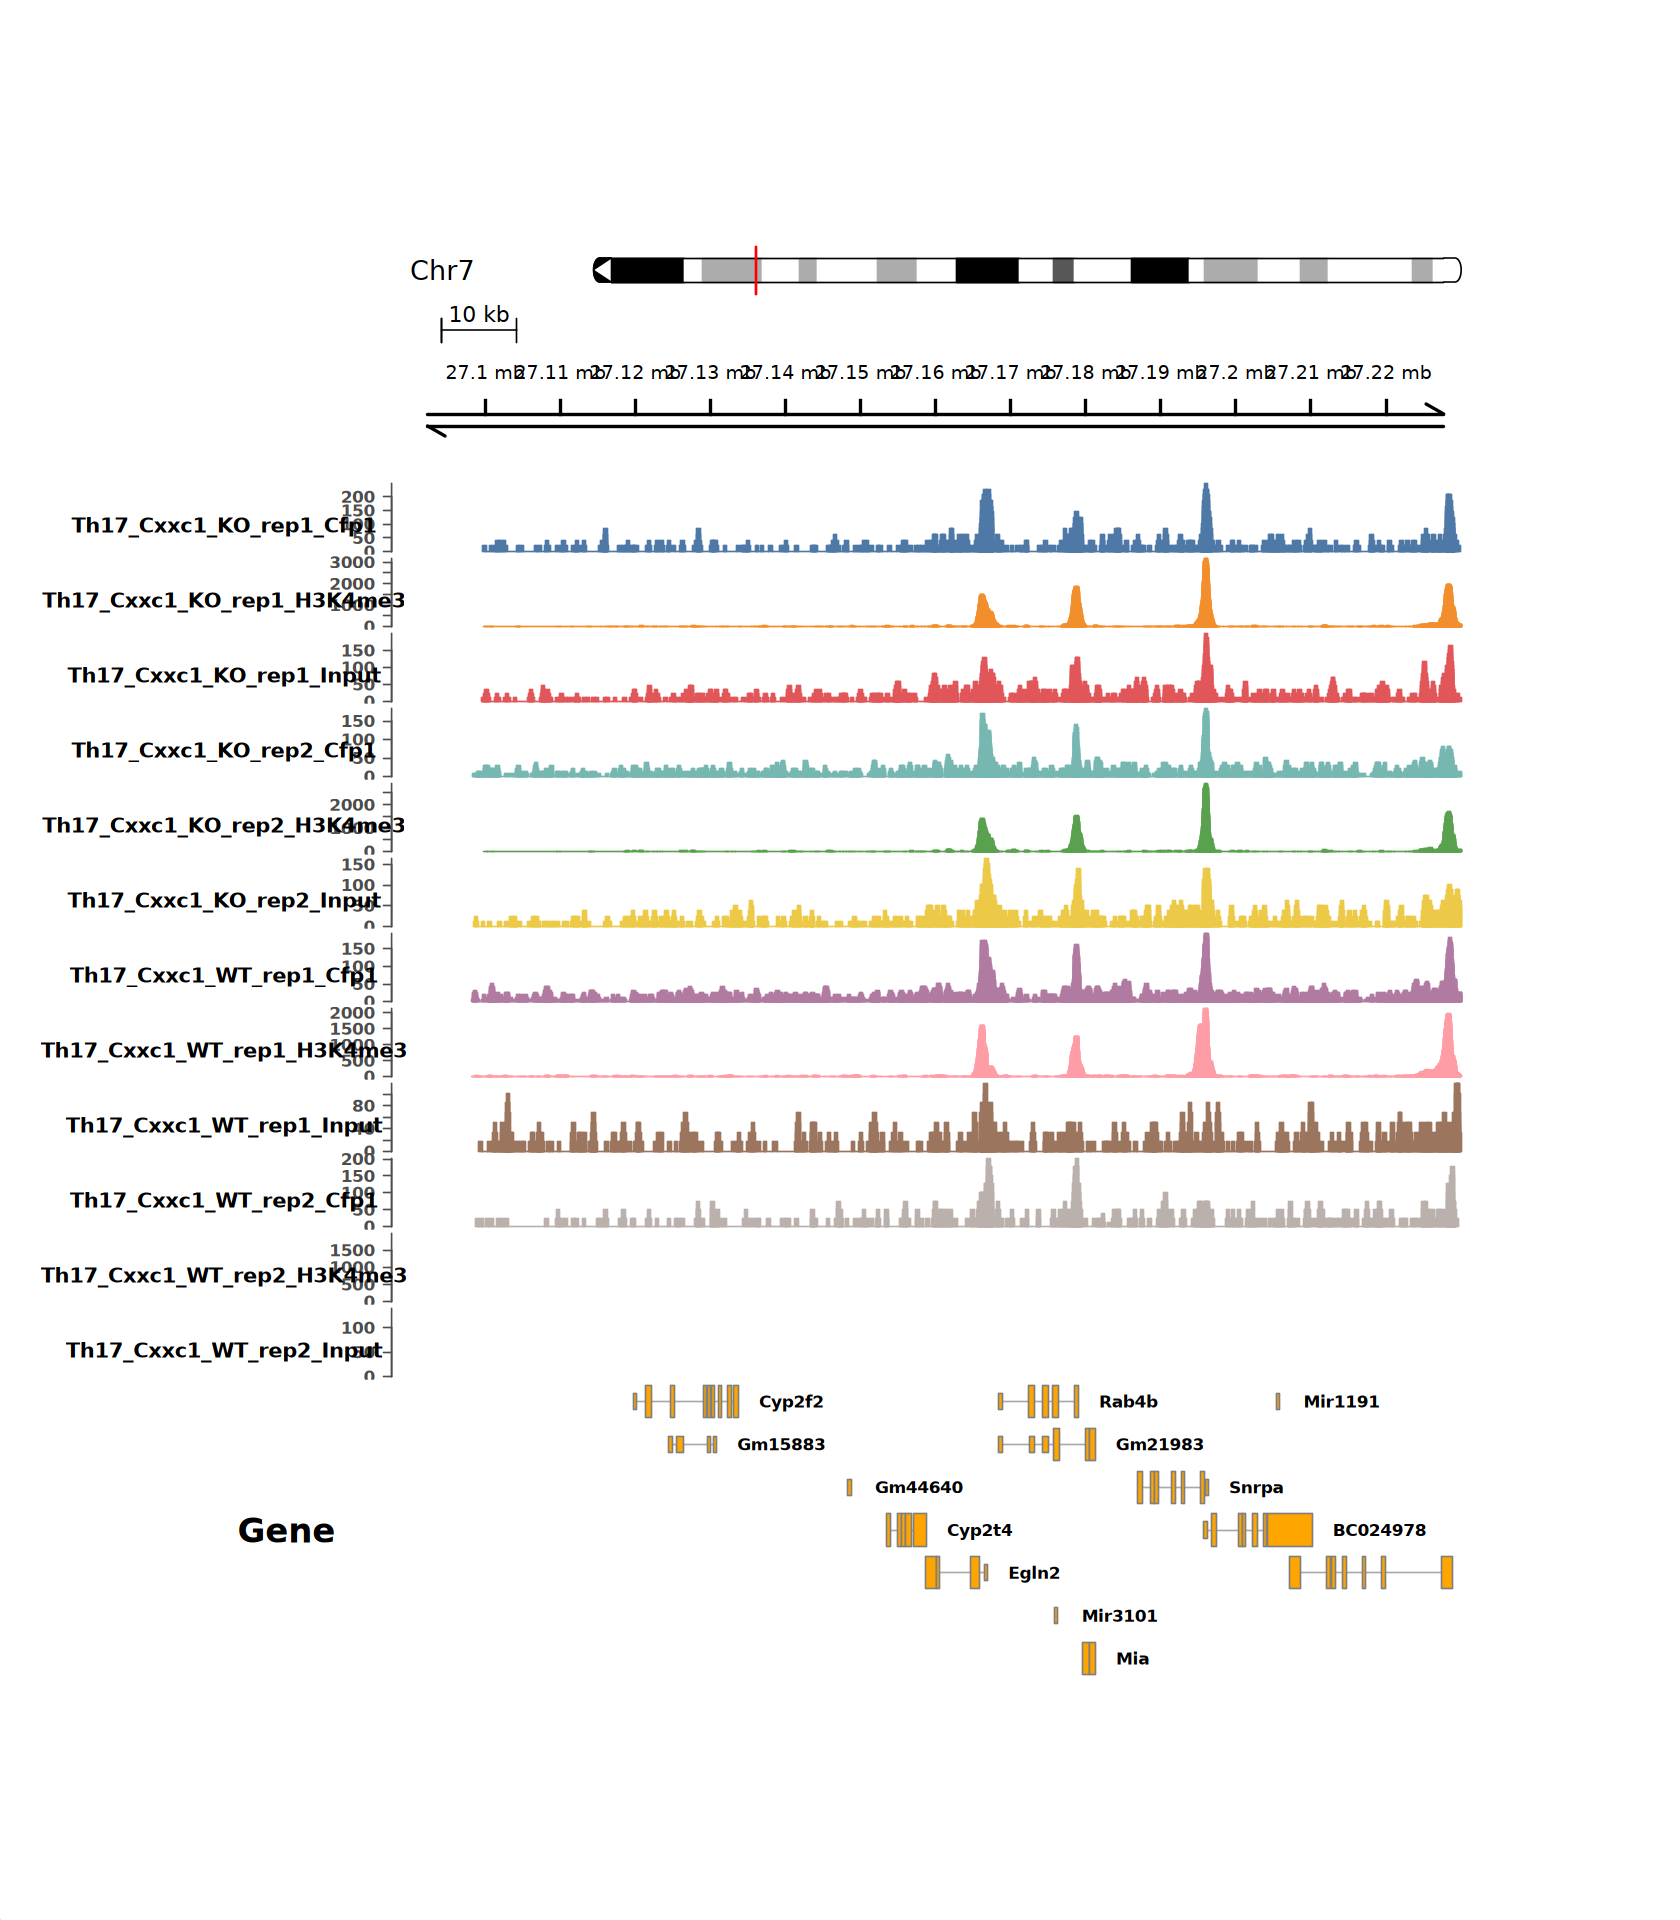

In [65]:
options(repr.plot.width = 14, repr.plot.height = 16)

track_list <- c(
    list(id_track, scale_track, axis_track),
    signal_tracks,
    list(gene_track)
)

plotTracks(
    trackList = track_list, 
    chromosome = chrom, 
    from = region_start, 
    to = region_end, 
    sizes = c(2, 2, 4, rep(2.5, length(signals_list)), 10), 
    background.title = "white", 
    col.title = "black", 
    col.axis = "grey30", 
    reverseStrand = FALSE, 
    rotation.title = 0, 
    title.width = 1, 
    just.group = "right", 
    extend.left = 0, 
    margin = 60
)

# * Reference

> 1. [The csaw Book](https://bioconductor.org/books/release/csawBook/)